# CS156 Session 2: Tensors, Linear Regression, and Logistic Regression

In this session, I explore how numerical data can be represented using tensors and then used by machine learning models. A tensor is a general way of organizing numbers; a vector is a one-dimensional tensor, while a matrix is a two-dimensional tensor.

The session focuses on two models:

- **Linear regression**, which predicts a continuous numerical value.
- **Logistic regression**, which predicts a class.

I first use scikit-learn to implement these models. I then examine their predictions, evaluate their errors, and finally implement both models from scratch to understand what `.fit()` is actually doing.

## Pre-Class Work: Linear and Logistic Regression on the Iris Dataset

### Question

How can I use the Iris dataset to fit a linear regression model and a logistic regression model, and what do their predictions look like?

### My Approach

The Iris dataset contains measurements from three species of Iris flowers. Each flower has four numerical measurements: sepal length, sepal width, petal length, and petal width.

For **linear regression**, I predict sepal length because it is a continuous numerical value. I use sepal width, petal length, petal width, and species as the input features.

For **logistic regression**, I predict the flower species. I use only sepal length and sepal width so that the classification regions can be visualized in two dimensions.

These models answer different questions. Linear regression asks, "What numerical value should I predict?" Logistic regression asks, "Which class should this observation belong to?"

Linear Regression
Mean Absolute Error: 0.2595570975563035
Mean Squared Error: 0.10174529564238954
Root Mean Squared Error: 0.3189753840696638

Logistic Regression
Accuracy: 0.82


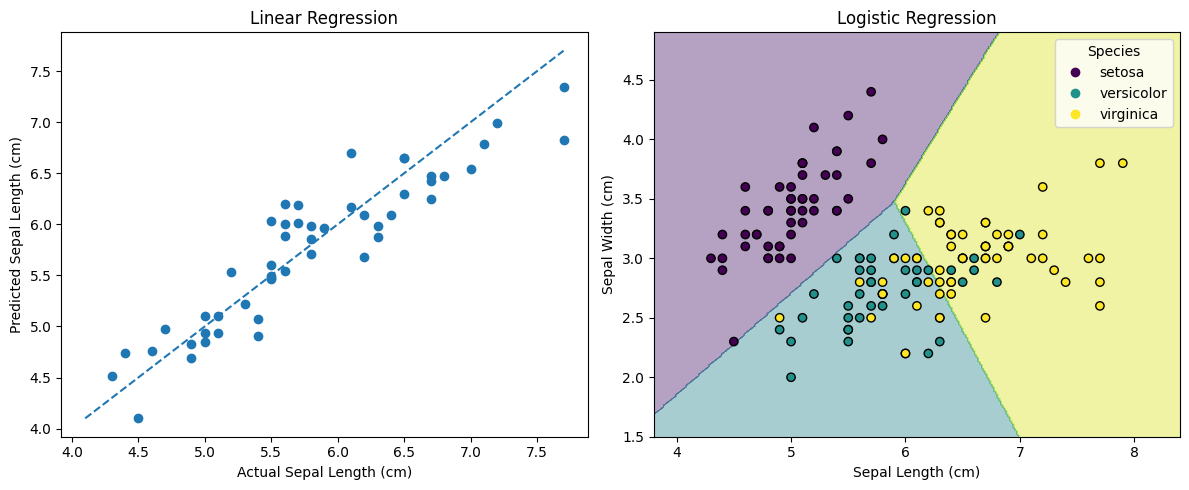

In [6]:
# Importing the libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error


def load_iris_data():
    """Loading the Iris dataset."""

    # Loading the flower measurements and species labels
    iris = load_iris()

    # Organizing the measurements in a DataFrame
    df = pd.DataFrame(iris.data, columns=iris.feature_names)

    # Adding numerical species labels
    df["target"] = iris.target

    # Adding readable species names
    df["target_name"] = df["target"].map(dict(enumerate(iris.target_names)))

    return df, iris


def fit_linear_regression(df):
    """Fitting linear regression to predict sepal length."""

    # Selecting measurements that may help predict sepal length
    X = df[["sepal width (cm)", "petal length (cm)", "petal width (cm)", "target"]]

    # Selecting the continuous value being predicted
    y = df["sepal length (cm)"]

    # Keeping some flowers separate for evaluating the fitted model
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.33, random_state=101)

    # Creating the linear regression model
    model = LinearRegression()

    # Learning the relationship between the features and sepal length
    model.fit(X_train, y_train)

    # Predicting sepal lengths for flowers the model did not train on
    predictions = model.predict(X_test)

    # Measuring how far the predictions are from the real values
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)

    print("Linear Regression")
    print("Mean Absolute Error:", mae)
    print("Mean Squared Error:", mse)
    print("Root Mean Squared Error:", rmse)

    return model, y_test, predictions


def fit_logistic_regression(df):
    """Fitting logistic regression to classify Iris species."""

    # Selecting two measurements so the decision regions can be visualized
    X = df[["sepal length (cm)", "sepal width (cm)"]].values

    # Selecting the flower species as the target
    y = df["target"].values

    # Creating a multiclass logistic regression model
    model = LogisticRegression(max_iter=200)

    # Learning boundaries between the three flower species
    model.fit(X, y)

    # Measuring how many training observations are classified correctly
    accuracy = model.score(X, y)

    print("\nLogistic Regression")
    print("Accuracy:", accuracy)

    return model, X, y


def visualize_models(y_test, predictions, log_model, X_log, y_log, iris):
    """Visualizing linear and logistic regression side-by-side."""

    # Creating one plot for each model
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plotting real and predicted sepal lengths
    axes[0].scatter(y_test, predictions)

    # Finding common limits for the actual and predicted values
    minimum = min(y_test.min(), predictions.min())
    maximum = max(y_test.max(), predictions.max())

    # Showing where perfectly accurate predictions would fall
    axes[0].plot([minimum, maximum], [minimum, maximum], linestyle="--")

    axes[0].set_xlabel("Actual Sepal Length (cm)")
    axes[0].set_ylabel("Predicted Sepal Length (cm)")
    axes[0].set_title("Linear Regression")

    # Finding the range of the two classification features
    x_min = X_log[:, 0].min() - 0.5
    x_max = X_log[:, 0].max() + 0.5
    y_min = X_log[:, 1].min() - 0.5
    y_max = X_log[:, 1].max() + 0.5

    # Creating many hypothetical flower measurements across the plot
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300))

    # Combining the coordinates into feature pairs
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Predicting a species for every position in the grid
    Z = log_model.predict(grid)
    Z = Z.reshape(xx.shape)

    # Showing the regions assigned to each predicted species
    axes[1].contourf(xx, yy, Z, alpha=0.4)

    # Showing the real flowers on top of the predicted regions
    scatter = axes[1].scatter(
        X_log[:, 0],
        X_log[:, 1],
        c=y_log,
        edgecolor="black")

    axes[1].legend(
        scatter.legend_elements()[0],
        iris.target_names,
        title="Species")

    axes[1].set_xlabel("Sepal Length (cm)")
    axes[1].set_ylabel("Sepal Width (cm)")
    axes[1].set_title("Logistic Regression")

    plt.tight_layout()
    plt.show()


# Loading the Iris dataset
df, iris = load_iris_data()

# Fitting the regression model
linear_model, y_test, predictions = fit_linear_regression(df)

# Fitting the classification model
logistic_model, X_log, y_log = fit_logistic_regression(df)

# Comparing both models visually
visualize_models(y_test, predictions, logistic_model, X_log, y_log, iris)

### Interpretation

The linear regression plot compares the real sepal lengths with the model's predictions. If the model predicted every flower perfectly, every point would lie directly on the dashed diagonal line. The points are close to this line but not exactly on it, so the model captures a substantial part of the relationship while still making errors.

The logistic regression plot shows something different. The background represents the regions that the model assigns to each Iris species, while the individual points represent real flowers. The boundaries are fairly simple because logistic regression learns linear decision boundaries.

One important limitation is that the logistic regression accuracy here is calculated on the same observations used to fit the model. Therefore, the reported accuracy describes training performance; it is not a strong estimate of performance on new flowers.

## Pre-Class Work: Linear and Logistic Regression on MNIST

### Question

How do linear and logistic regression behave when the inputs are images rather than simple flower measurements?

### My Approach

MNIST contains images of handwritten digits. Each original image is a 28 × 28 matrix of pixel intensities, so each image can be treated as a tensor.

I use only the digits 0, 1, and 2 to keep the example simple. Each 28 × 28 image is flattened into 784 numerical features, and the pixel values are scaled between 0 and 1.

I then use PCA to reduce these 784 features to two features. This makes the data easier to visualize, although it also removes information.

I compare linear regression and logistic regression on the same representation. Linear regression treats the labels 0, 1, and 2 as numerical values; logistic regression treats them as three separate classes. This comparison helps show why the type of model should match the type of prediction problem.

Linear Regression
Mean Absolute Error: 0.3845137357711792
Mean Squared Error: 0.23121067881584167
Root Mean Squared Error: 0.48084371558318373

Logistic Regression
Accuracy: 0.9233333333333333
Weighted F1 Score: 0.9232379132492048


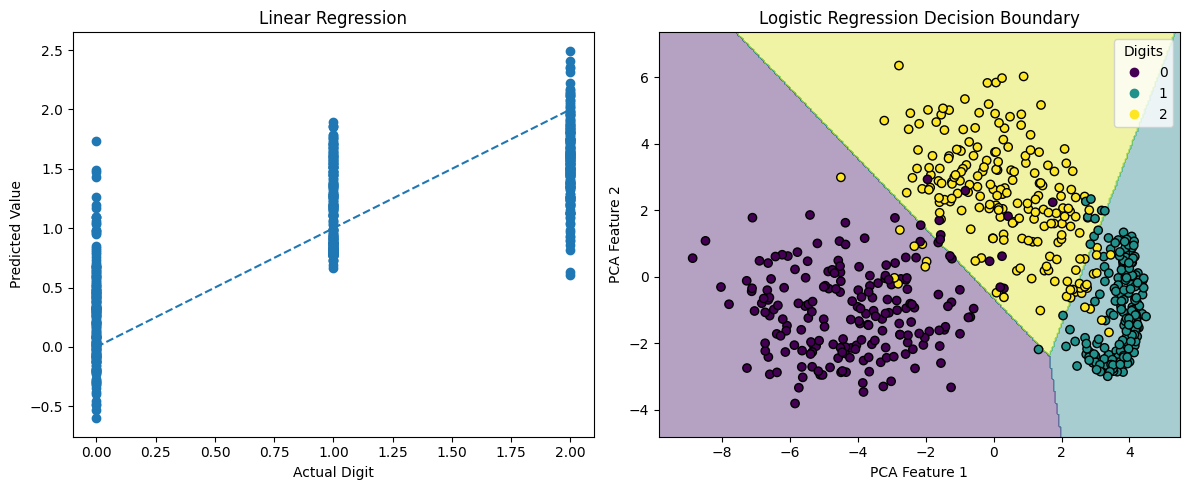

In [7]:
# Importing the libraries
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def load_mnist_data(samples_per_class=1000):
    """Loading a smaller MNIST dataset."""

    # Loading the handwritten digit images
    (X, y), _ = mnist.load_data()

    # Collecting examples of only digits 0, 1, and 2
    selected_indices = []

    for digit in [0, 1, 2]:
        # Finding images that belong to the current digit
        digit_indices = np.where(y == digit)[0]

        # Keeping the same number of images from each class
        selected_indices.extend(digit_indices[:samples_per_class])

    selected_indices = np.array(selected_indices)

    # Keeping only the selected images and labels
    X = X[selected_indices]
    y = y[selected_indices]

    # Converting each 28 x 28 image into a vector of 784 pixel values
    X = X.reshape(X.shape[0], -1)

    # Scaling pixel intensities from 0-255 to 0-1
    X = X.astype(np.float32) / 255.0

    return X, y


def prepare_data(X, y):
    """Splitting the data and creating a two-dimensional PCA representation."""

    # Keeping a separate test set and preserving the class proportions
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    # Reducing the 784 pixel features to two PCA features
    pca = PCA(n_components=2)

    # Learning the PCA directions from the training data only
    X_train_pca = pca.fit_transform(X_train)

    # Applying the same transformation to the test data
    X_test_pca = pca.transform(X_test)

    return X_train_pca, X_test_pca, y_train, y_test


def fit_linear_regression(X_train, X_test, y_train, y_test):
    """Fitting linear regression to the numerical digit labels."""

    # Creating the regression model
    model = LinearRegression()

    # Learning a linear relationship between PCA features and digit values
    model.fit(X_train, y_train)

    # Predicting continuous values for the test images
    predictions = model.predict(X_test)

    # Measuring the difference between predicted and real digit values
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)

    print("Linear Regression")
    print("Mean Absolute Error:", mae)
    print("Mean Squared Error:", mse)
    print("Root Mean Squared Error:", rmse)

    return model, predictions


def fit_logistic_regression(X_train, X_test, y_train, y_test):
    """Fitting logistic regression to classify the digits."""

    # Scaling the PCA features before logistic regression
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=500))

    # Learning boundaries between digits 0, 1, and 2
    model.fit(X_train, y_train)

    # Predicting the class of each test image
    predictions = model.predict(X_test)

    # Measuring classification performance
    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average="weighted")

    print("\nLogistic Regression")
    print("Accuracy:", accuracy)
    print("Weighted F1 Score:", f1)

    return model, predictions


def visualize_mnist_models(X_test, y_test, linear_predictions, logistic_model):
    """Comparing the two models using the two PCA features."""

    # Creating one plot for each model
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Comparing real digit labels with continuous regression predictions
    axes[0].scatter(y_test, linear_predictions)
    axes[0].plot([0, 2], [0, 2], linestyle="--")

    axes[0].set_xlabel("Actual Digit")
    axes[0].set_ylabel("Predicted Value")
    axes[0].set_title("Linear Regression")

    # Finding the range of the PCA features
    x_min = X_test[:, 0].min() - 1
    x_max = X_test[:, 0].max() + 1
    y_min = X_test[:, 1].min() - 1
    y_max = X_test[:, 1].max() + 1

    # Creating a grid across the two-dimensional feature space
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300))

    grid = np.c_[xx.ravel(), yy.ravel()]

    # Predicting the digit assigned to every location
    Z = logistic_model.predict(grid)
    Z = Z.reshape(xx.shape)

    # Showing the model's decision regions
    axes[1].contourf(xx, yy, Z, alpha=0.4)

    # Showing the actual test observations
    scatter = axes[1].scatter(
        X_test[:, 0],
        X_test[:, 1],
        c=y_test,
        edgecolor="black")

    axes[1].legend(
        scatter.legend_elements()[0],
        ["0", "1", "2"],
        title="Digits")

    axes[1].set_xlabel("PCA Feature 1")
    axes[1].set_ylabel("PCA Feature 2")
    axes[1].set_title("Logistic Regression Decision Boundary")

    plt.tight_layout()
    plt.show()


# Loading a balanced subset of MNIST
X, y = load_mnist_data()

# Creating training and test sets and reducing them to two PCA features
X_train, X_test, y_train, y_test = prepare_data(X, y)

# Fitting linear regression
linear_model, linear_predictions = fit_linear_regression(
    X_train, X_test, y_train, y_test)

# Fitting logistic regression
logistic_model, logistic_predictions = fit_logistic_regression(
    X_train, X_test, y_train, y_test)

# Visualizing both models
visualize_mnist_models(
    X_test, y_test, linear_predictions, logistic_model)

### Interpretation

The MNIST example makes the difference between regression and classification clearer.

Linear regression can technically predict the labels 0, 1, and 2, but its output is continuous. For example, it could predict 1.43 even though 1.43 is not a digit class. This happens because the model treats the labels as numbers on a continuous scale.

Logistic regression is more appropriate because the task is classification. It assigns each observation to one of the three possible classes.

The model achieves much stronger classification performance even though PCA reduces each image from 784 pixel values to only two features. However, this dimensionality reduction also throws away information; the two PCA features are mainly being used here so that I can visualize the classification problem.

# Question 1 of 3: Basic Questions for Class

## What is the Iris data? What real-world property is represented by the labels and numbers?

The Iris dataset contains measurements of individual flowers from three Iris species: setosa, versicolor, and virginica.

The numerical values represent physical measurements of the flowers:

- sepal length
- sepal width
- petal length
- petal width

The target label represents the flower's species. Therefore, the features describe measurable physical properties, while the label represents the biological category of the flower.

## What patterns do I see visually in the data? What might these patterns mean?

Some species occupy noticeably different regions of the feature space. Setosa is particularly easy to separate using several flower measurements, while versicolor and virginica overlap more.

This suggests that flower morphology contains information about species; however, the measurements do not separate every species perfectly.

## What patterns are the models trying to fit?

The linear regression model is trying to find a linear relationship between the input measurements and sepal length.

The logistic regression model is trying to find boundaries that separate the three Iris species. Because logistic regression is a linear model, these boundaries are linear in the feature space.

## What is a loss function?

A loss function measures how wrong a model's predictions are during training.

The model uses this value to decide how its parameters should change. Training attempts to find parameters that make the loss smaller.

For linear regression, squared error is commonly used. Large differences between a prediction and the real value produce a larger penalty.

For logistic regression, cross-entropy loss is commonly used. It penalizes the model when it gives low probability to the correct class.

## What is a metric?

A metric is a value that I use to evaluate and interpret model performance.

A loss function is mainly used to train the model, while a metric is mainly used to describe how well the resulting model performs. Sometimes the same mathematical quantity can serve both purposes.

Examples include RMSE for regression and accuracy or F1 score for classification.

## Residuals

A residual is the difference between the real value and the predicted value.

Residual = actual value - predicted value

If the residual is close to zero, the prediction is close to the real observation.

## Accuracy

Accuracy is the fraction of predictions that the classifier gets correct.

For example, an accuracy of 0.82 means that 82% of the observations were assigned the correct class.

## Sensitivity

Sensitivity measures how many of the actual positive examples the model correctly identifies.

It is also called recall:

Sensitivity = True Positives / (True Positives + False Negatives)

A high sensitivity means the model misses relatively few positive examples.

# Question 2 of 3: Core Questions

## Critique the two models. What real-world properties do they capture?

### Linear Regression

The linear regression model captures relationships between physical flower measurements. In this implementation, it uses sepal width, petal length, petal width, and species to predict sepal length.

The model assumes that these relationships can be represented as a weighted sum. This is useful because flower measurements are related, but it is still a simplification; biological relationships do not have to be perfectly linear.

Another important point is that species is included as a numerical feature. The labels 0, 1, and 2 are category codes, not measurements where species 2 is literally twice species 1. Treating the label as an ordinary continuous number introduces an artificial ordering.

### Logistic Regression

The logistic regression model uses sepal length and sepal width to distinguish the three flower species.

It captures the idea that species occupy different regions of measurement space. However, it only uses two of the four available flower measurements, so it ignores useful information from petal length and petal width.

The original implementation also calculates accuracy using the same data used to train the model. This tells me how well the model fits its training observations, but it does not directly measure how well it generalizes to unseen flowers.

## How can I measure how badly linear regression fits the data?

I can examine the residuals, which are the differences between actual and predicted values.

I can then summarize these errors using metrics such as:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)

RMSE is particularly useful because it gives larger errors more weight and remains in the same unit as the target variable.

## How can I measure how badly logistic regression fits the data?

For logistic regression, I can compare predicted classes with the real classes.

Useful measures include:

- accuracy
- precision
- recall or sensitivity
- F1 score
- confusion matrix
- cross-entropy loss

Accuracy gives an overall fraction of correct predictions, while a confusion matrix shows exactly which classes the model confuses.

## Implementing RMSE From Scratch

I use RMSE to measure the error of the Iris linear regression model.

First, I calculate each residual by subtracting the prediction from the real value. I square these residuals so that negative and positive errors cannot cancel each other out, then calculate their mean. Finally, I take the square root.

A smaller RMSE means that the predictions are closer to the real sepal lengths.

In [8]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split


def calculate_rmse(actual, predicted):
    """Calculating root mean squared error."""

    # Measuring the error of every prediction
    residuals = actual - predicted

    # Squaring the errors and averaging them
    mse = np.mean(residuals ** 2)

    # Returning the error to the original target units
    rmse = np.sqrt(mse)

    return rmse


# Re-extracting the correct Iris test targets
X_iris = df[["sepal width (cm)", "petal length (cm)", "petal width (cm)", "target"]]
y_iris = df["sepal length (cm)"]

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.33, random_state=101
)

# Creating and fitting a dedicated Iris linear model to avoid name collision with MNIST
local_iris_model = LinearRegression()
local_iris_model.fit(X_train_iris, y_train_iris)

# Getting predictions using the newly fitted model
iris_predictions = local_iris_model.predict(X_test_iris)

# Measuring the Iris linear regression predictions
rmse = calculate_rmse(y_test_iris, iris_predictions)

print("RMSE:", rmse)

RMSE: 0.3189753840696638


### Interpretation

The RMSE is approximately 0.319 cm for the original Iris model.

This means that the model's prediction error is roughly 0.319 cm in the RMSE sense. It does not mean that every prediction is wrong by exactly 0.319 cm; some residuals are smaller and others are larger.

RMSE also gives larger errors more influence because the residuals are squared before they are averaged.

## What is the model getting wrong? What is missing?

The models understand some useful patterns, but they also simplify the problems.

The linear regression model understands that several flower measurements are associated with sepal length. What it misses is any relationship that cannot be represented well by a linear combination of the features. It also treats the numerical species code as though the spacing between species values has mathematical meaning.

The logistic regression model understands that different species tend to occupy different parts of the sepal-length and sepal-width space. However, versicolor and virginica overlap, so two features cannot separate every flower correctly.

The implementation also reveals an important distinction between fitting and evaluation. A model can fit patterns in its training data without perfectly reproducing every observation; more importantly, matching every training observation is not necessarily the goal. I want a model that captures a useful pattern that can also work on new data.

This is why I should not judge a model only by whether it reproduces its training examples.

# Extension Question: What Does It Mean to Fit the Data?

## Why don't these models simply match the data perfectly?

The models are not memorizing every observation. Instead, they search for a set of parameters that makes a chosen loss function as small as possible.

For linear regression, the parameters are weights that determine how strongly each feature contributes to the predicted value.

For logistic regression, the parameters determine class scores and therefore the probabilities assigned to each class.

The models have limited mathematical forms. Linear regression can only construct a linear combination of the features, while logistic regression creates linear decision boundaries before converting the resulting scores into class probabilities.

Because real data contain overlap, noise, and relationships that may not follow these exact forms, the best available parameters can still leave prediction errors.

Fitting therefore means finding parameters that produce a good overall solution according to the model's loss function; it does not necessarily mean passing directly through every training observation.

## Extension: Linear Regression From Scratch

### Question

What is scikit-learn doing when I call `LinearRegression().fit()`?

### My Approach

I recreate linear regression using gradient descent.

The model starts with weights equal to zero. During every iteration, it:

1. uses the current weights to make predictions;
2. measures the prediction errors;
3. calculates the gradient of the squared-error loss;
4. changes the weights in the direction that reduces the loss.

This process gradually finds weights that provide a better overall fit to the training observations.

In [9]:
# Linear Regression from Scratch using the Iris Dataset

import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


# Loading the Iris dataset
iris = load_iris()

# Selecting features for predicting sepal length
X = np.c_[
    iris.data[:, 1],  # sepal width
    iris.data[:, 2],  # petal length
    iris.data[:, 3],  # petal width
    iris.target]      # species label

# Selecting sepal length as the continuous target
y = iris.data[:, 0]

# Creating separate training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=101)

# Finding the training-set mean and standard deviation
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

# Standardizing both sets using only training-set statistics
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Adding a column of ones so the model can learn an intercept
X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]

# Starting all model parameters at zero
weights = np.zeros(X_train.shape[1])

# Controlling how quickly and how long the model learns
learning_rate = 0.05
iterations = 2000

for i in range(iterations):

    # Combining the features and current weights to make predictions
    predictions = X_train @ weights

    # Measuring how far the predictions are from the real values
    errors = predictions - y_train

    # Calculating how each weight contributes to squared error
    gradient = (2 / len(X_train)) * X_train.T @ errors

    # Moving the weights in the direction that reduces the loss
    weights = weights - learning_rate * gradient

# Using the learned weights on unseen flowers
test_predictions = X_test @ weights

# Measuring the final prediction error
rmse = np.sqrt(np.mean((test_predictions - y_test) ** 2))

print("Learned weights:", weights)
print("RMSE:", rmse)

Learned weights: [ 5.864       0.27658529  1.41724636 -0.45952732 -0.14078925]
RMSE: 0.31876717773791186


### Interpretation

The important part of this code is the training loop.

`predictions = X_train @ weights` produces the model's current prediction. The residuals then show how wrong those predictions are.

The gradient tells me how the squared-error loss would change if each weight changed slightly. I subtract the gradient from the weights, scaled by the learning rate; repeating this operation gradually lowers the error.

The final RMSE is approximately the same as the scikit-learn implementation. This shows that the library is not performing a mysterious operation; it is finding parameters that minimize prediction error, although scikit-learn may use a different numerical solution internally.

## Extension: Logistic Regression From Scratch

### Question

What is scikit-learn doing when I call `LogisticRegression().fit()`?

### My Approach

There are three Iris species, so I implement multiclass logistic regression using softmax.

For each flower, the model first calculates three scores, one for each possible species. Softmax converts these scores into probabilities that add up to 1.

The model then compares the predicted probabilities with the correct classes. Cross-entropy loss penalizes the model when it gives the correct species a low probability.

Gradient descent updates the weights so that, over many iterations, the probability assigned to the correct species generally increases.

In [10]:
# Logistic Regression from Scratch using the Iris Dataset

import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


# Loading the Iris dataset
iris = load_iris()

# Using two flower measurements as classification features
X = iris.data[:, :2]

# Using the species labels as the target
y = iris.target

# Creating training and testing datasets while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=101, stratify=y)

# Finding training-set scaling values
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

# Standardizing the features
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Adding a bias feature
X_train = np.c_[np.ones(len(X_train)), X_train]
X_test = np.c_[np.ones(len(X_test)), X_test]

# Converting species labels into one-hot vectors
num_classes = 3
y_one_hot = np.eye(num_classes)[y_train]

# Creating one set of weights for each class
weights = np.zeros((X_train.shape[1], num_classes))


def softmax(z):
    """Converting class scores into probabilities."""

    # Shifting the scores to make the exponential calculation stable
    z = z - np.max(z, axis=1, keepdims=True)

    # Converting each class score into a positive value
    exp_z = np.exp(z)

    # Normalizing the values so each row sums to one
    probabilities = exp_z / np.sum(exp_z, axis=1, keepdims=True)

    return probabilities


# Controlling the gradient-descent process
learning_rate = 0.1
iterations = 3000

for i in range(iterations):

    # Calculating one score for every class
    scores = X_train @ weights

    # Converting the scores into class probabilities
    probabilities = softmax(scores)

    # Measuring how the predicted probabilities differ from the true classes
    gradient = X_train.T @ (probabilities - y_one_hot) / len(X_train)

    # Updating the weights to reduce cross-entropy loss
    weights = weights - learning_rate * gradient

# Calculating class probabilities for unseen flowers
test_probabilities = softmax(X_test @ weights)

# Selecting the class with the largest predicted probability
test_predictions = np.argmax(test_probabilities, axis=1)

# Measuring the fraction of correct test predictions
accuracy = np.mean(test_predictions == y_test)

print("Learned weights:")
print(weights)

print("Accuracy:", accuracy)

Learned weights:
[[-1.78971469  1.22554181  0.56417289]
 [-4.29604848  1.28620611  3.00984238]
 [ 2.42740534 -1.34165268 -1.08575266]]
Accuracy: 0.78


### Interpretation

The central idea is similar to linear regression: the model repeatedly changes its weights to reduce a loss.

However, the output has a different meaning.

`X_train @ weights` produces three class scores for each flower. Softmax converts these scores into probabilities. For example, one flower might receive probabilities of 0.90 for setosa, 0.08 for versicolor, and 0.02 for virginica.

The model does not directly move a decision boundary by hand. Instead, it changes the weights so that the correct classes receive larger probabilities and incorrect classes receive smaller probabilities.

After training, I use `argmax` to choose whichever species has the highest probability.

The test accuracy is lower than perfect because sepal length and sepal width do not completely separate all three Iris species. Versicolor and virginica overlap in this two-dimensional representation.

# Final Interpretation

This session helped me separate three ideas that initially look similar: representation, model fitting, and evaluation.

First, the data must be represented numerically. Iris observations are vectors of flower measurements, while MNIST images begin as 28 × 28 tensors of pixel values.

Second, fitting means learning model parameters. Linear regression learns weights that reduce numerical prediction error; logistic regression learns weights that make the correct classes more probable.

Finally, evaluation asks whether those learned patterns actually produce useful predictions. Regression metrics such as RMSE measure numerical error, while classification metrics such as accuracy and F1 measure errors in class predictions.

The main point is that a model is not trying to memorize every observation. It uses a restricted mathematical function and searches for parameters that provide a good overall fit. Because the representation and the model both impose limits, some residual error is expected.